In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, datasets
import matplotlib.pyplot as plt

In [2]:
# Load CIFAR-10, normalise images and one-hot encode labels
def load_data():
    (x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()
    x_train, x_test = x_train / 255.0, x_test / 255.0
    y_train = tf.keras.utils.to_categorical(y_train, 10)
    y_test = tf.keras.utils.to_categorical(y_test, 10)
    return (x_train, y_train), (x_test, y_test)

# Build CNN model
def create_model():
    model = models.Sequential()
    model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu'))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dense(10, activation='softmax'))
    return model

# Compile model
def compile_model(model):
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

# Train model
def train_model(model, x_train, y_train, x_test, y_test):
    history = model.fit(
        x_train,
        y_train,
        epochs=10,
        validation_data=(x_test, y_test),
        batch_size=64
    )
    return history

# Plot training and validation accuracy
def plot_history(history):
    plt.plot(history.history['accuracy'], label='accuracy')
    plt.plot(history.history['val_accuracy'], label='val_accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.ylim([0, 1])
    plt.legend(loc='lower right')
    plt.show()

C:\Users\renai\PycharmProjects\LDNN\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.4068 - loss: 1.6268 - val_accuracy: 0.5125 - val_loss: 1.3516
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5522 - loss: 1.2595 - val_accuracy: 0.5641 - val_loss: 1.2069
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.6102 - loss: 1.1006 - val_accuracy: 0.6092 - val_loss: 1.0899
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.6514 - loss: 0.9944 - val_accuracy: 0.6479 - val_loss: 1.0076
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6731 - loss: 0.9270 - val_accuracy: 0.6674 - val_loss: 0.9463
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6976 - loss: 0.8650 - val_accuracy: 0.6655 - val_loss: 0.9651
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7128 - loss: 0.8169 - val_accuracy: 0.6863 - val_loss: 0.9205
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7277 - loss: 0.7799 - val

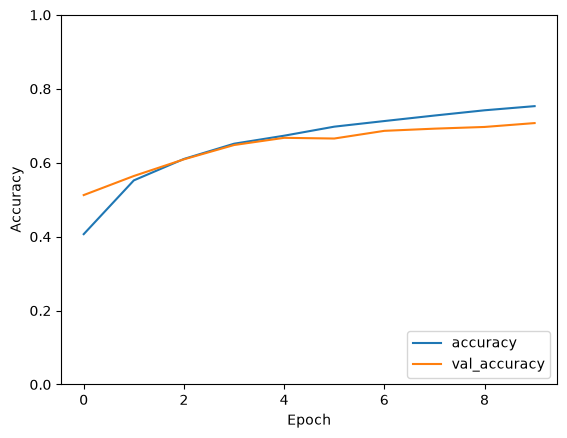

In [3]:
if __name__ == "__main__":
    # Load data
    (x_train, y_train), (x_test, y_test) = load_data()

    # Build, compile and train model
    model = create_model()
    compile_model(model)
    history = train_model(model, x_train, y_train, x_test, y_test)

    # Evaluate model
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
    print(f"Test accuracy: {test_acc:.2f}")

    # Plot accuracy curves
    plot_history(history)